# 03 · Orientación de los datos (E3)

En el cuaderno 02 vimos que, con una nube alargada en dirección diagonal (E2), iForest ordena peor la periferia que
el EIF. En este cuaderno aislamos la causa. Generamos normales bivariantes
$$
N_2\big(\mathbf{0},\ \mathbf{R}_\theta \operatorname{diag}(\lambda, 1) \mathbf{R}_\theta^\top\big),
\qquad \lambda \in \{1, 4, 16\}, \quad \theta \in \{0^\circ, 15^\circ, 30^\circ, 45^\circ\},
$$
donde $\mathbf{R}_\theta$ gira la nube un ángulo $\theta$, de modo que el eje mayor de la elipse forma un ángulo
$\theta$ con el primer eje, y $\sqrt{\lambda}$ es la razón entre los semiejes. Con $\lambda = 1$ la distribución es
esférica y el giro no cambia nada; con $\lambda = 16$ la nube es cuatro veces más larga que ancha.

En cada réplica, las doce combinaciones de $\lambda$ y $\theta$ comparten la semilla, de modo que sus muestras son
transformaciones lineales de una misma muestra $N_2(\mathbf{0}, I)$. La profundidad de Tukey es afín invariante, así
que ordena exactamente igual las doce muestras de una réplica; cualquier cambio en la concordancia se debe, por tanto,
al método de aislamiento.

In [1]:
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from isolation_forest import iforest, longitudes
from eif import eif, longitudes_eif
from escenarios import normal_rotada
from profundidad import hd_muestral
from metricas import metricas_par
import visualizacion as V

PSI, T, HLIM = 256, 100, 255
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## Una réplica: nube alargada sin girar y girada $45^\circ$

Tomamos la primera réplica de E3 (semilla $3000$) con $\lambda = 16$ y dos orientaciones: $\theta = 0^\circ$, con el
eje mayor paralelo al primer eje, y $\theta = 45^\circ$, en diagonal. Construimos los dos bosques sobre cada muestra y
evaluamos la longitud de ruta media y la profundidad de Tukey en una malla de puntos que cubre la nube. Los mapas se
representan por rangos: las zonas claras son las más centrales según cada medida.

In [2]:
semilla = 3000
mapas, muestras, tablas = {}, {}, {}
for theta in (0, 45):
    esc = normal_rotada(f"E3 lambda=16 theta={theta}", 1000, 16, theta)
    X, _ = esc.muestrear(np.random.default_rng(semilla))
    G, x, y = V.malla(X, puntos=100)
    random.seed(semilla)
    B_if = iforest(X, t=T, psi=PSI)
    random.seed(semilla)
    B_eif = eif(X, t=T, psi=PSI)
    mapas[f"iForest, θ = {theta}°"] = longitudes(G, B_if, HLIM).mean(axis=1)
    mapas[f"EIF, θ = {theta}°"] = longitudes_eif(G, B_eif, HLIM).mean(axis=1)
    mapas[f"Tukey, θ = {theta}°"] = hd_muestral(X, G)
    muestras[theta] = (X, x, y)
    hd = hd_muestral(X)
    tablas[theta] = pd.DataFrame({
        "iForest": metricas_par(longitudes(X, B_if, HLIM).mean(axis=1), hd),
        "EIF": metricas_par(longitudes_eif(X, B_eif, HLIM).mean(axis=1), hd)}).T.rename(columns=V.MEDIDAS)

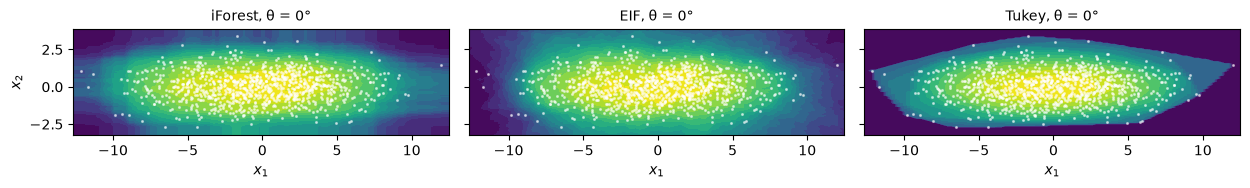

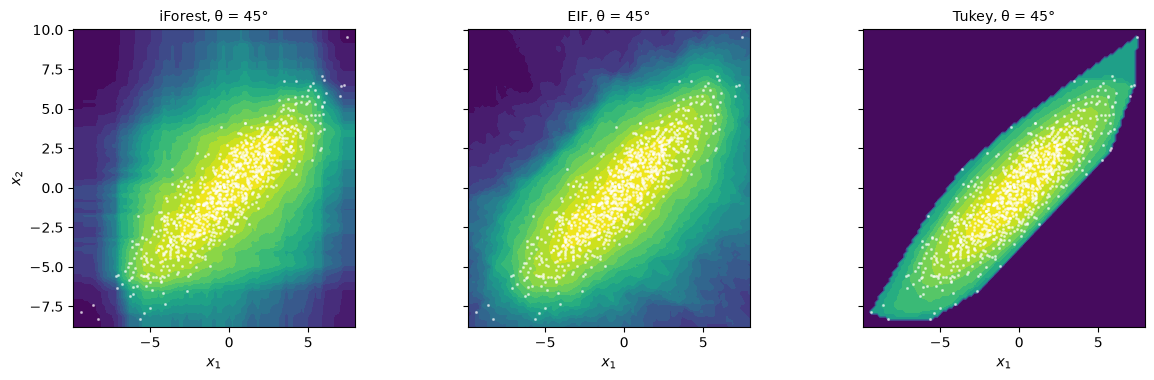

In [3]:
for theta in (0, 45):
    X, x, y = muestras[theta]
    fig = V.dibujar_mapas_malla(X, x, y, {k: v for k, v in mapas.items() if k.endswith(f"{theta}°")})
    V.guardar(fig, f"E3_mapas_theta{theta}")
    plt.show()

Con el eje mayor paralelo al primer eje ($\theta = 0^\circ$), los mapas de iForest y del EIF siguen la forma de la nube. Con la nube girada ($\theta = 45^\circ$), en los mapas de iForest aparecen bandas paralelas a los ejes coordenados, que no siguen la orientación de la elipse; los del EIF son más suaves y giran con la nube. La profundidad de Tukey vale $0$ fuera de la envolvente convexa de la muestra, por lo que en su mapa toda esa región tiene el mismo color.

Las medidas de concordancia de esta réplica son:

In [4]:
pd.concat(tablas, names=["θ (grados)", "método"])

$\tau_b$  $\rho_S$  $r_{\log}$  $\xi_n$  Solapamiento 5 %  $\tau_b$ centro  $\tau_b$ periferia
θ (grados) método                                                                                                 
0          iForest     0.843     0.964       0.977    0.777              0.90            0.564               0.812
           EIF         0.813     0.944       0.970    0.733              0.82            0.434               0.755
45         iForest     0.758     0.919       0.930    0.660              0.59            0.400               0.493
           EIF         0.836     0.964       0.961    0.746              0.72            0.605               0.624

## Resultados sobre las 100 réplicas

Representamos la media de $\tau_b$ y del solapamiento del $5\,\%$ frente al ángulo de giro, para cada valor de
$\lambda$ y cada método. La línea gris es el techo, que es el mismo para todas las combinaciones de una réplica porque
las dos profundidades de Tukey, la muestral y la poblacional, son afín invariantes.

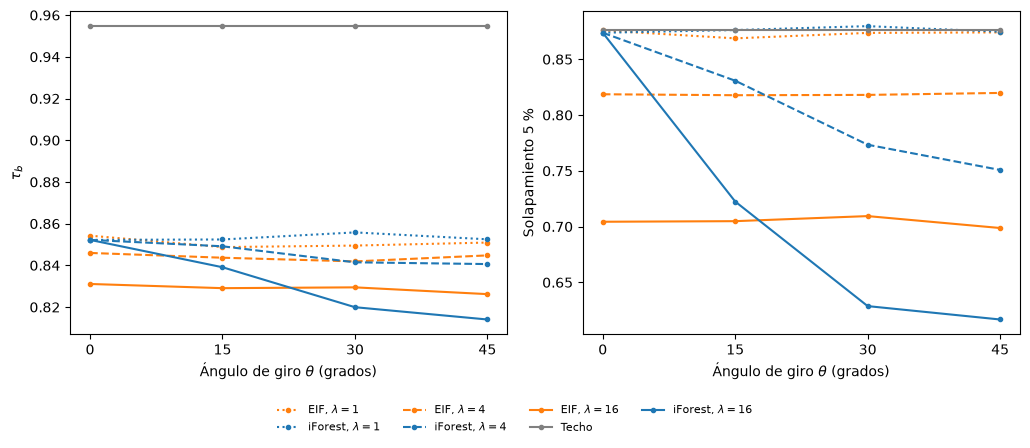

In [5]:
E3 = pd.read_csv("../results/E3.csv")
fig = V.dibujar_frente_a_theta(E3)
V.guardar(fig, "E3_theta")
plt.show()

La tabla recoge los valores con la nube más alargada ($\lambda = 16$), y la siguiente compara los dos métodos
réplica a réplica.

In [6]:
V.tabla_resumen(E3[E3["lam"] == 16])

R       $\tau_b$       $\rho_S$     $r_{\log}$        $\xi_n$ Solapamiento 5 % $\tau_b$ centro $\tau_b$ periferia
escenario             método                                                                                                                      
E3 lambda=16 theta=0  Techo    100  0.955 (0.012)  0.997 (0.002)  0.987 (0.005)  0.927 (0.018)    0.876 (0.040)   0.917 (0.028)      0.830 (0.040)
                      iForest  100  0.852 (0.019)  0.967 (0.009)  0.977 (0.003)  0.781 (0.026)    0.874 (0.031)   0.611 (0.066)      0.808 (0.027)
                      EIF      100  0.831 (0.019)  0.961 (0.010)  0.960 (0.005)  0.750 (0.024)    0.704 (0.042)   0.597 (0.070)      0.634 (0.040)
E3 lambda=16 theta=15 Techo    100  0.955 (0.012)  0.997 (0.002)  0.987 (0.005)  0.927 (0.018)    0.876 (0.040)   0.917 (0.028)      0.830 (0.040)
                      iForest  100  0.839 (0.017)  0.964 (0.008)  0.964 (0.005)  0.761 (0.023)    0.722 (0.048)   0.613 (0.058)      0.648 (0.045)
                      EIF      100  0.829 (0.020)  0.960 (0.010)  0.960 (0.006)  0.747 (0.027)    0.705 (0.048)   0.595 (0.063)      0.632 (0.041)
E3 lambda=16 theta=30 Techo    100  0.955 (0.012)  0.997 (0.002)  0.987 (0.005)  0.927 (0.018)    0.876 (0.040)   0.917 (0.028)      0.830 (0.040)
                      iForest  100  0.820 (0.017)  0.957 (0.009)  0.947 (0.007)  0.732 (0.023)    0.629 (0.043)   0.597 (0.059)      0.540 (0.048)
                      EIF      100  0.829 (0.017)  0.960 (0.008)  0.960 (0.006)  0.747 (0.023)    0.709 (0.049)   0.594 (0.060)      0.633 (0.044)
E3 lambda=16 theta=45 Techo    100  0.955 (0.012)  0.997 (0.002)  0.987 (0.005)  0.927 (0.018)    0.876 (0.040)   0.917 (0.028)      0.830 (0.040)
                      iForest  100  0.814 (0.021)  0.955 (0.011)  0.941 (0.008)  0.724 (0.028)    0.617 (0.044)   0.594 (0.064)      0.514 (0.045)
                      EIF      100  0.826 (0.020)  0.959 (0.010)  0.958 (0.007)  0.743 (0.027)    0.699 (0.044)   0.595 (0.064)      0.617 (0.049)

In [7]:
V.comparacion_pareada(E3[E3["lam"] == 16], medidas=("tau_b", "r_log", "xi", "sol05"))

diferencia media réplicas a favor del EIF  p de Wilcoxon
escenario             medida                                                                    
E3 lambda=16 theta=0  $\tau_b$                    -0.021                 18 / 100      8.151e-13
                      $r_{\log}$                  -0.017                  0 / 100      3.897e-18
                      $\xi_n$                     -0.032                 16 / 100      6.265e-14
                      Solapamiento 5 %            -0.169                  0 / 100      3.888e-18
E3 lambda=16 theta=15 $\tau_b$                    -0.010                 31 / 100      4.097e-05
                      $r_{\log}$                  -0.004                 30 / 100      4.319e-07
                      $\xi_n$                     -0.014                 32 / 100      3.918e-05
                      Solapamiento 5 %            -0.018                 31 / 100      8.166e-04
E3 lambda=16 theta=30 $\tau_b$                     0.009                 67 / 100      5.423e-05
                      $r_{\log}$                   0.013                 97 / 100      5.113e-18
                      $\xi_n$                      0.015                 67 / 100      2.043e-05
                      Solapamiento 5 %             0.081                 97 / 100      1.351e-17
E3 lambda=16 theta=45 $\tau_b$                     0.012                 72 / 100      2.494e-05
                      $r_{\log}$                   0.017                 99 / 100      5.269e-18
                      $\xi_n$                      0.019                 71 / 100      5.051e-06
                      Solapamiento 5 %             0.082                 99 / 100      5.564e-18

## Observaciones

- **Con la distribución esférica ($\lambda = 1$) el giro no cambia nada.** Los dos métodos tienen $\tau_b \approx 0.85$,
  $r_{\log} \approx 0.98$ y un solapamiento del $5\,\%$ de $0.87$–$0.88$, igual que el techo ($0.876$).
- **Sin giro ($\theta = 0^\circ$), el alargamiento no afecta a iForest.** Con $\lambda = 1$, $4$ y $16$, iForest da
  $\tau_b = 0.852$, $r_{\log} = 0.977$ y un solapamiento de $0.874$. Alargar la nube en la dirección de un eje es un
  cambio de escala de esa coordenada, y una transformación afín coordenada a coordenada no cambia ninguna longitud de
  ruta de iForest (lo comprueba `experiments/verificacion.py`).
- **Al girar una nube alargada, iForest empeora, sobre todo en la periferia.** Con $\lambda = 16$, el solapamiento del
  $5\,\%$ baja de $0.874$ con $\theta = 0^\circ$ a $0.617$ con $\theta = 45^\circ$, la $\tau_b$ de la periferia de
  $0.808$ a $0.514$ y $r_{\log}$ de $0.977$ a $0.941$. La $\tau_b$ global baja menos ($0.852$ a $0.814$) y la del
  centro apenas cambia ($\approx 0.60$): el giro desordena sobre todo las observaciones menos centrales. Es el mismo
  efecto que en E2.
- **El EIF no depende del giro, pero sí del alargamiento.** Con $\lambda = 16$, su solapamiento es de $0.70$–$0.71$
  y su $r_{\log}$ de $0.958$–$0.960$ para cualquier $\theta$; con $\lambda = 4$, su solapamiento es de $0.82$. Por eso,
  sin giro, el EIF es claramente peor que iForest ($0.704$ frente a $0.874$; ninguna de las 100 réplicas es favorable
  al EIF), y solo lo supera a partir de $\theta = 30^\circ$ (a favor en 97 réplicas con $30^\circ$ y en 99 con
  $45^\circ$, tanto en el solapamiento como en $r_{\log}$).
- **Conclusión.** Los cortes paralelos a los ejes hacen que iForest dependa de la orientación de los datos, a
  diferencia de la profundidad de Tukey, que es afín invariante. El EIF elimina la dependencia de la orientación, pero
  no la del alargamiento, de modo que es preferible cuando la nube está alargada en una dirección oblicua e iForest
  cuando está alineada con los ejes.